In [1]:
import pandas as pd
import numpy as np



In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error

In [4]:
df = pd.read_csv(r'D:\GenAI\Data\rawdata\usa_housing_kaggle.csv')

In [5]:
df.head()

,Price,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,ZipCode,CrimeRate,SchoolRating
0,221958,1,1.9,4827,1979,2,1.45,82240,48.60,5
1,771155,2,2.0,1035,1987,2,1.75,74315,92.03,9
2,231932,1,3.0,2769,1982,1,1.46,79249,52.08,3
3,465838,3,3.3,2708,1907,3,1.62,80587,61.65,1
4,359178,4,3.4,1175,1994,2,0.74,20756,15.66,4


In [6]:
df.shape

(300, 10)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Price         300 non-null    int64  
 1   Bedrooms      300 non-null    int64  
 2   Bathrooms     300 non-null    float64
 3   SquareFeet    300 non-null    int64  
 4   YearBuilt     300 non-null    int64  
 5   GarageSpaces  300 non-null    int64  
 6   LotSize       300 non-null    float64
 7   ZipCode       300 non-null    int64  
 8   CrimeRate     300 non-null    float64
 9   SchoolRating  300 non-null    int64  
dtypes: float64(3), int64(7)
memory usage: 23.6 KB


In [8]:
df.describe()

,Price,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,ZipCode,CrimeRate,SchoolRating
count,300.000000,300.000000,300.000000,300.00000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,522761.916667,2.966667,2.464000,3052.75000,1962.616667,1.513333,1.062200,54324.770000,49.324033,5.096667
std,256922.348275,1.451175,0.886184,1194.97144,36.005431,1.116832,0.543896,24718.938552,28.833220,2.674165
min,112666.000000,1.000000,1.000000,840.00000,1902.000000,0.000000,0.110000,10163.000000,0.190000,1.000000
25%,299936.500000,2.000000,1.700000,2053.50000,1931.750000,1.000000,0.570000,34175.000000,22.547500,3.000000
50%,505806.500000,3.000000,2.400000,3127.00000,1961.000000,1.000000,1.085000,54896.500000,49.970000,5.000000
75%,744603.750000,4.000000,3.200000,4081.00000,1994.000000,3.000000,1.482500,74108.000000,74.402500,8.000000
max,999684.000000,5.000000,4.000000,4997.00000,2022.000000,3.000000,2.000000,99881.000000,99.710000,9.000000


In [9]:
df.isnull().sum()

Price           0
Bedrooms        0
Bathrooms       0
SquareFeet      0
YearBuilt       0
GarageSpaces    0
LotSize         0
ZipCode         0
CrimeRate       0
SchoolRating    0
dtype: int64

In [11]:
X=df.drop(["Price","ZipCode"],axis=1)
Y=df['Price']

In [12]:
X.head()

,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,CrimeRate,SchoolRating
0,1,1.9,4827,1979,2,1.45,48.60,5
1,2,2.0,1035,1987,2,1.75,92.03,9
2,1,3.0,2769,1982,1,1.46,52.08,3
3,3,3.3,2708,1907,3,1.62,61.65,1
4,4,3.4,1175,1994,2,0.74,15.66,4


In [13]:
Y.head()

0    221958
1    771155
2    231932
3    465838
4    359178
Name: Price, dtype: int64

In [14]:
X_train,X_test,Y_Train,Y_Test = train_test_split(X,Y,random_state=40,test_size=0.2)

In [15]:
X_train.shape

(240, 8)

In [17]:
X_test.shape

(60, 8)

In [19]:
Y_Train.shape

(240,)

In [20]:
Y_Test.shape

(60,)

In [21]:
model=LinearRegression()

In [22]:
model

LinearRegression()

In [23]:
model.fit(X_train,Y_Train)

LinearRegression()

In [24]:
Y_predict=model.predict(X_test)

In [28]:

comparison = pd.DataFrame({
    'Actual Price': Y_Test.values,
    'Predicted Price': Y_predict
})

comparison.head()


,Actual Price,Predicted Price
0,300235,499885.340691
1,481050,553318.219960
2,369536,520921.247291
3,580671,501685.094772
4,679879,525100.021289


In [29]:
print(mean_squared_error(Y_Test,Y_predict))

63342678076.02349


In [30]:
print(root_mean_squared_error(Y_Test,Y_predict))

251679.71327865004


In [33]:
print("MAE :", mean_absolute_error(Y_Test, Y_predict))


MAE : 220886.0356781331


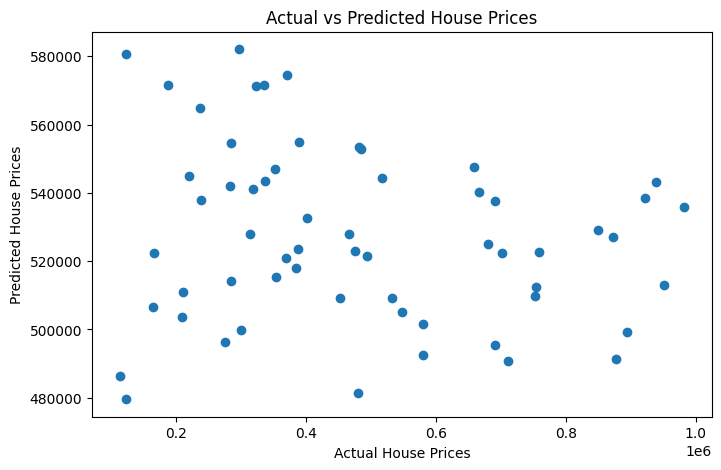

In [34]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(Y_Test, Y_predict)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()


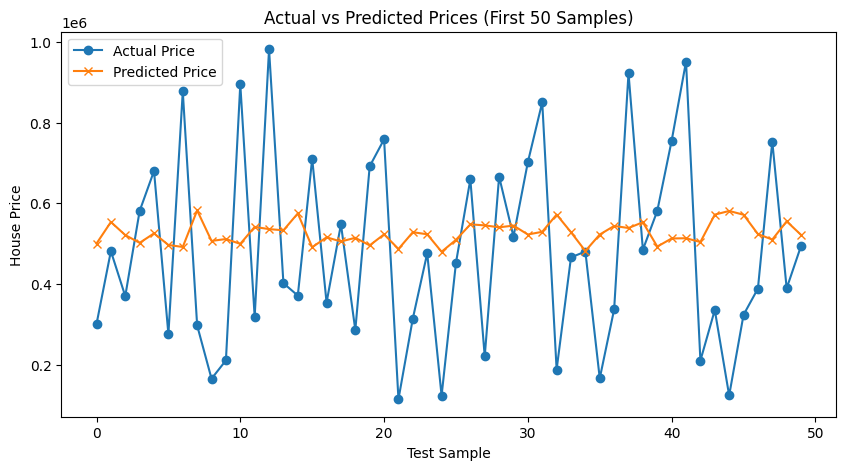

In [35]:

plt.figure(figsize=(10, 5))

plt.plot(Y_Test.values[:50], label="Actual Price", marker='o')
plt.plot(Y_predict[:50], label="Predicted Price", marker='x')

plt.xlabel("Test Sample")
plt.ylabel("House Price")
plt.title("Actual vs Predicted Prices (First 50 Samples)")

plt.legend()
plt.show()


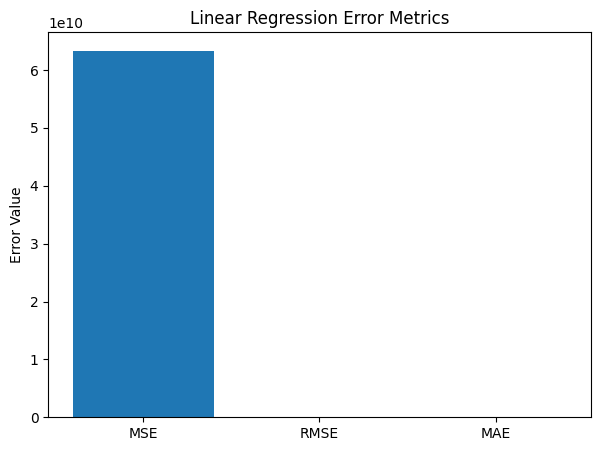

In [36]:

mse = mean_squared_error(Y_Test, Y_predict)
rmse = np.sqrt(mse)
mae = mean_absolute_error(Y_Test, Y_predict)

errors = {
    "MSE": mse,
    "RMSE": rmse,
    "MAE": mae
}

plt.figure(figsize=(7, 5))
plt.bar(errors.keys(), errors.values())

plt.title("Linear Regression Error Metrics")
plt.ylabel("Error Value")

plt.show()


NameError: name 'Y_test' is not defined